In [130]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from ucimlrepo import fetch_ucirepo 
import matplotlib.pyplot as plt
import random
from zonolayer import fit_zonolayer, predict_zonolayer, compute_ipm_bounds
from sklearn.model_selection import train_test_split
from SadeghiINN import SadeghiINN
from torch.utils.data import TensorDataset, DataLoader

def set_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

In [131]:
def extract_latent_features(model, x):
    model.eval()
    with torch.no_grad():
        preds, features = model(x, return_features=True)
    return preds.cpu().numpy(), features.cpu().numpy()

## Artificial Example #2

Epoch 50: MSE = 0.008435
Epoch 100: MSE = 0.000333
Epoch 150: MSE = 0.000154
Epoch 200: MSE = 0.000120
Epoch 250: MSE = 0.000099
Epoch 300: MSE = 0.000086
Epoch 350: MSE = 0.000078
Epoch 400: MSE = 0.000072
Epoch 450: MSE = 0.000067
Epoch 500: MSE = 0.000064
Epoch 550: MSE = 0.000061
Epoch 600: MSE = 0.000059
Epoch 650: MSE = 0.000057
Epoch 700: MSE = 0.000072
Epoch 750: MSE = 0.000056
Epoch 800: MSE = 0.000055
Epoch 850: MSE = 0.000054
Epoch 900: MSE = 0.000053
Epoch 950: MSE = 0.000057
Epoch 1000: MSE = 0.000053
Epoch 1050: MSE = 0.000052
Epoch 1100: MSE = 0.000051
Epoch 1150: MSE = 0.000050
Epoch 1200: MSE = 0.000049
Epoch 1250: MSE = 0.000048
Epoch 1300: MSE = 0.000050
Epoch 1350: MSE = 0.000048
Epoch 1400: MSE = 0.000047
Epoch 1450: MSE = 0.000046
Epoch 1500: MSE = 0.000045
Epoch 1550: MSE = 0.000045
Epoch 1600: MSE = 0.000087
Epoch 1650: MSE = 0.000044
Epoch 1700: MSE = 0.000044
Epoch 1750: MSE = 0.000043
Epoch 1800: MSE = 0.000043
Epoch 1850: MSE = 0.000042
Epoch 1900: MSE = 0.0

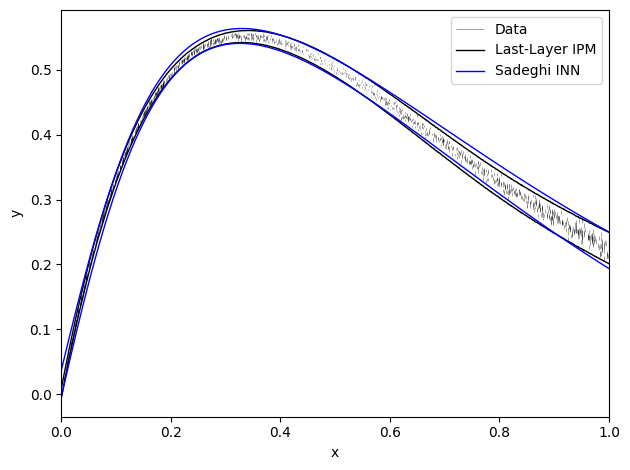

In [132]:
def nonlinear_data(n):
    n_samples = n
    x = np.random.rand(n_samples)
    w = np.random.normal(0, 0.025, n_samples)
    y = 0.3 * (15 * x * np.exp(-3 * x) + w * x)
    y_radius = (1/160) * (np.abs(x - 0.5) + 0.1)
    y_lower = y - y_radius
    y_upper = y + y_radius

    x_grid = np.linspace(0, 10, n_samples)

    return n_samples, x, y, y_lower, y_upper, x_grid


n, x, y, y_lower, y_upper, x_grid = nonlinear_data(1240)

# Tensor conversion for PyTorch
y_lb_t = torch.tensor(y_lower, dtype=torch.float32).unsqueeze(1)
y_ub_t = torch.tensor(y_upper, dtype=torch.float32).unsqueeze(1)
x_t = torch.tensor(x, dtype=torch.float32).unsqueeze(1)

class RegressionNetwork(nn.Module):
    def __init__(self, input_dim=1, hidden_dim=10, zono_dim=8):
        super().__init__()
        self.feature_extractor = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, zono_dim),
            nn.Tanh()
        )
        self.regressor = nn.Linear(zono_dim, 1)

    def forward(self, x, return_features=False):
        features = self.feature_extractor(x)
        out = self.regressor(features)
        if return_features:
            return out, features
        return out


def train_centre(x_t, y_lb_t, y_ub_t, epochs=2000, lr=0.01, print_every=50):
    y_mid = (y_lb_t + y_ub_t) / 2

    centre_net = RegressionNetwork(input_dim=x_t.shape[1])
    optimizer = torch.optim.Adam(centre_net.parameters(), lr=lr, weight_decay=1e-4)
    criterion = nn.MSELoss()

    for epoch in range(epochs):
        pred = centre_net(x_t)
        loss = criterion(pred, y_mid)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if (epoch + 1) % print_every == 0:
            print(f"Epoch {epoch+1}: MSE = {loss.item():.6f}")

    return centre_net


x_grid = np.linspace(0, 1, n).reshape(-1, 1)

centre_net = train_centre(x_t, y_lb_t, y_ub_t)
pred_train, latent_train = extract_latent_features(centre_net, x_t)
pred_test, latent_test = extract_latent_features(centre_net, torch.tensor(x_grid, dtype=torch.float32))

# zonolayer_fit = fit_zonolayer(latent_train, y_lower, y_upper)
# zonolayer = predict_zonolayer(zonolayer_fit, latent_test)
ipm_upper, ipm_lower = compute_ipm_bounds(latent_train, latent_test, y_lower, y_upper)

# Sadeghi INN
train_loader = DataLoader(TensorDataset(x_t, y_lb_t, y_ub_t),
                          batch_size=200, shuffle=True)
inn = SadeghiINN(input_dim=1, hidden_dims=[10, 8])
inn.fit(train_loader, epochs=2000, lr=0.01, decay_steps=200)
# inn.calibrate(x_t, y_lb_t, y_ub_t)

sadeghi_lower, sadeghi_upper = inn.predict_interval(torch.tensor(x_grid, dtype=torch.float32))
sadeghi_lower = sadeghi_lower.numpy().ravel()
sadeghi_upper = sadeghi_upper.numpy().ravel()

# yl_zl = np.asarray(zonolayer["y_lower"]).ravel()
# yu_zl = np.asarray(zonolayer["y_upper"]).ravel()
# midpoint_model = np.asarray(zonolayer["midpoint"]).ravel()

x_plot = x_grid.squeeze()
ipm_lower = np.asarray(ipm_lower).ravel()
ipm_upper = np.asarray(ipm_upper).ravel()

fig, ax = plt.subplots()

ax.vlines(x, y_lower, y_upper,
          color='black', alpha=0.5, linewidth=0.5, label='Data')

# # Zonolayer
# ax.plot(x_plot, yl_zl, 'r--', lw=2, label='Zonolayer')
# ax.plot(x_plot, yu_zl, 'r--', lw=2)

# Last-layer IPM
ax.plot(x_plot, ipm_lower, color='black', lw=1, label='Last-Layer IPM')
ax.plot(x_plot, ipm_upper, color='black', lw=1)

# Sadeghi INN
ax.plot(x_plot, sadeghi_lower, color='blue', lw=1, label='Sadeghi INN')
ax.plot(x_plot, sadeghi_upper, color='blue', lw=1)

# Zonolayer midpoint
# ax.plot(x_plot, midpoint_model, 'r-', lw=1.5)

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_xlim(0, 1)
ax.legend()
fig.tight_layout()

fig.savefig("PDF/LastLayerIPM_Campi.pdf", bbox_inches="tight")
plt.show()

### Multivarate Example - Heating Load

Epoch 50: MSE = 0.112981
Epoch 100: MSE = 0.076416
Epoch 150: MSE = 0.073885
Epoch 200: MSE = 0.068296
Epoch 250: MSE = 0.060381
Epoch 300: MSE = 0.055025
Epoch 350: MSE = 0.046432
Epoch 400: MSE = 0.032834
Epoch 450: MSE = 0.019393
Epoch 500: MSE = 0.012406
Epoch 550: MSE = 0.011694
Epoch 600: MSE = 0.007631
Epoch 650: MSE = 0.006355
Epoch 700: MSE = 0.005664
Epoch 750: MSE = 0.005161
Epoch 800: MSE = 0.004769
Epoch 850: MSE = 0.004450
Epoch 900: MSE = 0.009857
Epoch 950: MSE = 0.004030
Epoch 1000: MSE = 0.003824
Epoch 1050: MSE = 0.003662
Epoch 1100: MSE = 0.003514
Epoch 1150: MSE = 0.003865
Epoch 1200: MSE = 0.003372
Epoch 1250: MSE = 0.003263
Epoch 1300: MSE = 0.003183
Epoch 1350: MSE = 0.003114
Epoch 1400: MSE = 0.003056
Epoch 1450: MSE = 0.005799
Epoch 1500: MSE = 0.003072
Epoch 1550: MSE = 0.003012
Epoch 1600: MSE = 0.002976
Epoch 1650: MSE = 0.002946
Epoch 1700: MSE = 0.002921
Epoch 1750: MSE = 0.002900
Epoch 1800: MSE = 0.002882
Epoch 1850: MSE = 0.003305
Epoch 1900: MSE = 0.0

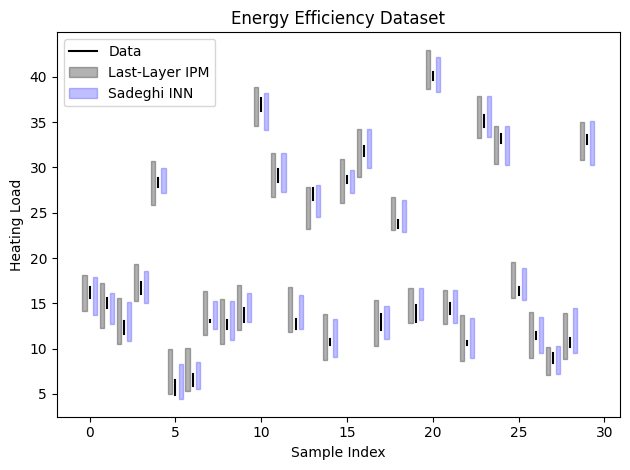

In [133]:
# Load and Intervalise
df = pd.read_csv('Data/energy_efficiency_data.csv')
X = df.drop(columns=['Heating_Load', 'Cooling_Load'])
y_heating = df['Heating_Load'].values

def intervalise_heating_load(y):
    n = len(y)
    r = np.abs(np.random.normal(loc=0.5, scale=0.25, size=n))
    b = np.random.uniform(low=-1.0, high=1.0, size=n)
    m = y - r + (1 + b) * r
    return pd.DataFrame({"y": y, "y_lower": m - r, "y_upper": m + r})

intervals = intervalise_heating_load(y_heating)

# Split and Normalize
X_train, X_test, y_low_tr, y_low_te, y_up_tr, y_up_te = train_test_split(
    X.values, intervals['y_lower'].values, intervals['y_upper'].values, test_size=0.25, random_state=42
)

X_min, X_max = X_train.min(axis=0), X_train.max(axis=0)
X_train = (X_train - X_min) / (X_max - X_min)
X_test = (X_test - X_min) / (X_max - X_min)
y_mid_tr, y_rad_tr = (y_low_tr + y_up_tr) / 2, (y_up_tr - y_low_tr) / 2
y_mean, y_std = y_mid_tr.mean(), y_mid_tr.std()

# Normalise both bounds
y_low_tr = (y_low_tr - y_mean) / y_std
y_up_tr  = (y_up_tr  - y_mean) / y_std

class CentreNet(nn.Module):
    def __init__(self, input_dim=8, hidden_dim=12, zono_dim=8):
        super().__init__()
        self.feature_extractor = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, zono_dim),
            nn.Tanh()
        )
        self.regressor = nn.Linear(zono_dim, 1)

    def forward(self, x, return_features=False):
        features = self.feature_extractor(x)
        out = self.regressor(features)
        if return_features:
            return out, features
        return out


def train_centre(x_t, y_lb_t, y_ub_t, epochs=2000, lr=0.01, print_every=50):
    y_mid = ((y_lb_t + y_ub_t) / 2).reshape(-1, 1)
    
    centre_net = CentreNet(input_dim=x_t.shape[1])
    optimizer = torch.optim.Adam(centre_net.parameters(), lr=lr, weight_decay=1e-4)
    criterion = nn.MSELoss()
    for epoch in range(epochs):
        pred = centre_net(x_t) 
        loss = criterion(pred, y_mid)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        if (epoch + 1) % print_every == 0:
            print(f"Epoch {epoch+1}: MSE = {loss.item():.6f}")
    return centre_net


x_t = torch.tensor(X_train, dtype=torch.float32)
y_lb_t = torch.tensor(y_low_tr, dtype=torch.float32)
y_ub_t = torch.tensor(y_up_tr, dtype=torch.float32)

# Zonolayer computation
centre_net = train_centre(x_t, y_lb_t, y_ub_t)
pred_train, latent_train = extract_latent_features(centre_net, x_t)
pred_test, latent_test = extract_latent_features(centre_net, torch.tensor(X_test, dtype=torch.float32))
# zonolayer_fit = fit_zonolayer(latent_train, y_low_tr, y_up_tr)
# zonolayer = predict_zonolayer(zonolayer_fit, latent_test) 

# # Denormalise for plotting
# yl_zl = zonolayer["y_lower"] * y_std + y_mean
# yu_zl = zonolayer["y_upper"] * y_std + y_mean
# midpoint_model = zonolayer["midpoint"] * y_std + y_mean


ipm_upper, ipm_lower = compute_ipm_bounds(latent_train, latent_test, y_low_tr, y_up_tr)

ipm_upper = (ipm_upper.flatten() * y_std) + y_mean
ipm_lower = (ipm_lower.flatten() * y_std) + y_mean

y_lb_col = y_lb_t.reshape(-1, 1)
y_ub_col = y_ub_t.reshape(-1, 1)

train_loader = DataLoader(TensorDataset(x_t, y_lb_col, y_ub_col),
                          batch_size=128, shuffle=True)

inn = SadeghiINN(input_dim=X_train.shape[1], hidden_dims=[12, 12, 8])
inn.fit(train_loader, epochs=2000, lr=0.01, decay_steps=200)

x_test_t = torch.tensor(X_test, dtype=torch.float32)
s_lo, s_up = inn.predict_interval(x_test_t)
sadeghi_lower = s_lo.numpy().ravel() * y_std + y_mean
sadeghi_upper = s_up.numpy().ravel() * y_std + y_mean

# Plotting (30 Samples)
n_plot = 30
idx = np.sort(np.random.choice(len(X_test), n_plot, replace=False))

plt.figure()

ipm_offset     = -0.30
zono_offset    =  0.0
sadeghi_offset =  0.30
width = 0.12

for i, val in enumerate(idx):
    plt.plot([i, i], [y_low_te[val], y_up_te[val]],
             color='black', lw=1.5, zorder=3,
             label='Data' if i == 0 else "")

    # plt.fill_between([i - width + zono_offset, i + width + zono_offset],
    #                  yl_zl[val], yu_zl[val],
    #                  color='red', alpha=0.25,
    #                  label='Zonolayer' if i == 0 else "")

    plt.fill_between([i - width + ipm_offset, i + width + ipm_offset],
                     ipm_lower[val], ipm_upper[val],
                     color='black', alpha=0.3,
                     label='Last-Layer IPM' if i == 0 else "")

    plt.fill_between([i - width + sadeghi_offset, i + width + sadeghi_offset],
                     sadeghi_lower[val], sadeghi_upper[val],
                     color='blue', alpha=0.25,
                     label='Sadeghi INN' if i == 0 else "")

plt.title("Energy Efficiency Dataset")
plt.xlabel("Sample Index")
plt.ylabel("Heating Load")
plt.legend()
plt.tight_layout()
plt.savefig("PDF/HeatingLoadIPM.pdf", bbox_inches="tight")
plt.show()
